In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sqlalchemy import text, create_engine, URL

print("Libraries imported successfully!")

Libraries imported successfully!


In [9]:
username = "root"
password = "Kuber@123"
server = "localhost"
port = 3306
database = "Car2Insights"

connection_url = URL.create(
    drivername="mysql+pymysql",
    username=username,
    password=password,
    host=server,
    port=port,
    database=database
)

engine = create_engine(connection_url)

with engine.connect() as conn:
    result = conn.execute(text("SELECT DATABASE()"))
    print("Connected Database:", result.scalar())

Connected Database: car2insights


In [10]:
with engine.connect() as conn:
    result = conn.execute(text("SHOW TABLES"))

    print("Available Tables:")
    for row in result:
        print("-", row[0])

Available Tables:
- customers
- geolocation
- order_items
- order_payments
- order_reviews
- orders
- product_category_translation
- products
- sellers


In [11]:
create_order_features = """
DROP TABLE IF EXISTS order_features;

CREATE TABLE order_features AS

WITH item_totals AS
(
    SELECT
        order_id,
        SUM(price + freight_value) AS total_order_value
    FROM order_items
    GROUP BY order_id
),

customer_stats AS
(
    SELECT
        o.customer_id,
        COUNT(DISTINCT o.order_id) AS customer_order_count,
        SUM(COALESCE(it.total_order_value, 0)) AS customer_total_spending
    FROM orders o
    LEFT JOIN item_totals it
        ON o.order_id = it.order_id
    GROUP BY o.customer_id
),

review_stats AS
(
    SELECT
        order_id,
        AVG(review_score) AS avg_review_score
    FROM order_reviews
    GROUP BY order_id
),

payment_first AS
(
    SELECT
        order_id,
        payment_type
    FROM
    (
        SELECT
            order_id,
            payment_type,
            ROW_NUMBER() OVER
            (
                PARTITION BY order_id
                ORDER BY payment_sequential
            ) AS rn
        FROM order_payments
    ) p
    WHERE rn = 1
)

SELECT
    o.order_id,
    o.customer_id,
    o.order_status,

    o.order_purchase_timestamp,
    o.order_delivered_customer_date,
    o.order_estimated_delivery_date,

    COALESCE(it.total_order_value, 0)
        AS total_order_value,

    CASE
        WHEN o.order_delivered_customer_date IS NOT NULL
        THEN DATEDIFF(
            o.order_delivered_customer_date,
            o.order_purchase_timestamp
        )
        ELSE NULL
    END AS delivery_days,

    CASE
        WHEN o.order_delivered_customer_date IS NOT NULL
         AND o.order_estimated_delivery_date IS NOT NULL
        THEN GREATEST(
            DATEDIFF(
                o.order_delivered_customer_date,
                o.order_estimated_delivery_date
            ),
            0
        )
        ELSE NULL
    END AS delivery_delay_days,

    CASE
        WHEN o.order_delivered_customer_date IS NULL
            THEN 'Not Delivered'

        WHEN o.order_delivered_customer_date
             <= o.order_estimated_delivery_date
            THEN 'On Time'

        ELSE 'Delayed'
    END AS delivery_status,

    cs.customer_order_count,

    cs.customer_total_spending,

    ROUND(
        cs.customer_total_spending /
        NULLIF(cs.customer_order_count, 0),
        2
    ) AS average_order_value,

    CASE
        WHEN cs.customer_order_count > 1
            THEN 1
        ELSE 0
    END AS repeat_customer,

    rs.avg_review_score,

    pf.payment_type

FROM orders o

LEFT JOIN item_totals it
    ON o.order_id = it.order_id

LEFT JOIN customer_stats cs
    ON o.customer_id = cs.customer_id

LEFT JOIN review_stats rs
    ON o.order_id = rs.order_id

LEFT JOIN payment_first pf
    ON o.order_id = pf.order_id;
"""

with engine.begin() as conn:

    # MySQL does not execute multiple statements
    # through one execute(), so execute each statement separately.

    conn.execute(text("DROP TABLE IF EXISTS order_features"))

    conn.execute(text("""
        CREATE TABLE order_features AS

        WITH item_totals AS
        (
            SELECT
                order_id,
                SUM(price + freight_value) AS total_order_value
            FROM order_items
            GROUP BY order_id
        ),

        customer_stats AS
        (
            SELECT
                o.customer_id,
                COUNT(DISTINCT o.order_id) AS customer_order_count,
                SUM(COALESCE(it.total_order_value, 0))
                    AS customer_total_spending
            FROM orders o
            LEFT JOIN item_totals it
                ON o.order_id = it.order_id
            GROUP BY o.customer_id
        ),

        review_stats AS
        (
            SELECT
                order_id,
                AVG(review_score) AS avg_review_score
            FROM order_reviews
            GROUP BY order_id
        ),

        payment_first AS
        (
            SELECT
                order_id,
                payment_type
            FROM
            (
                SELECT
                    order_id,
                    payment_type,
                    ROW_NUMBER() OVER
                    (
                        PARTITION BY order_id
                        ORDER BY payment_sequential
                    ) AS rn
                FROM order_payments
            ) p
            WHERE rn = 1
        )

        SELECT
            o.order_id,
            o.customer_id,
            o.order_status,
            o.order_purchase_timestamp,
            o.order_delivered_customer_date,
            o.order_estimated_delivery_date,

            COALESCE(
                it.total_order_value,
                0
            ) AS total_order_value,

            CASE
                WHEN o.order_delivered_customer_date IS NOT NULL
                THEN DATEDIFF(
                    o.order_delivered_customer_date,
                    o.order_purchase_timestamp
                )
                ELSE NULL
            END AS delivery_days,

            CASE
                WHEN o.order_delivered_customer_date IS NOT NULL
                 AND o.order_estimated_delivery_date IS NOT NULL
                THEN GREATEST(
                    DATEDIFF(
                        o.order_delivered_customer_date,
                        o.order_estimated_delivery_date
                    ),
                    0
                )
                ELSE NULL
            END AS delivery_delay_days,

            CASE
                WHEN o.order_delivered_customer_date IS NULL
                    THEN 'Not Delivered'

                WHEN o.order_delivered_customer_date
                     <= o.order_estimated_delivery_date
                    THEN 'On Time'

                ELSE 'Delayed'
            END AS delivery_status,

            cs.customer_order_count,
            cs.customer_total_spending,

            ROUND(
                cs.customer_total_spending /
                NULLIF(cs.customer_order_count, 0),
                2
            ) AS average_order_value,

            CASE
                WHEN cs.customer_order_count > 1
                    THEN 1
                ELSE 0
            END AS repeat_customer,

            rs.avg_review_score,
            pf.payment_type

        FROM orders o

        LEFT JOIN item_totals it
            ON o.order_id = it.order_id

        LEFT JOIN customer_stats cs
            ON o.customer_id = cs.customer_id

        LEFT JOIN review_stats rs
            ON o.order_id = rs.order_id

        LEFT JOIN payment_first pf
            ON o.order_id = pf.order_id
    """))

print("order_features created successfully.")

order_features created successfully.


In [12]:
with engine.connect() as conn:
    result = conn.execute(
        text("SELECT COUNT(*) FROM order_features")
    )

    print("order_features rows:", result.scalar())

order_features rows: 99441


In [13]:
order_features = pd.read_sql(
    "SELECT * FROM order_features LIMIT 10",
    engine
)

order_features

,order_id,customer_id,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,total_order_value,delivery_days,delivery_delay_days,delivery_status,customer_order_count,customer_total_spending,average_order_value,repeat_customer,avg_review_score,payment_type
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29,72.19,7,0,On Time,1,72.19,72.19,0,5.0,credit_card
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15,259.83,16,0,On Time,1,259.83,259.83,0,4.0,credit_card
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05,216.87,8,0,On Time,1,216.87,216.87,0,5.0,credit_card
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-14 13:32:39,2018-08-20,25.78,6,0,On Time,1,25.78,25.78,0,4.0,credit_card
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-03-01 16:42:31,2017-03-17,218.04,25,0,On Time,1,218.04,218.04,0,5.0,credit_card
5,00048cc3ae777c65dbb7d2a0634bc1ea,816cbea969fe5b689b39cfc97a506742,delivered,2017-05-15 21:42:34,2017-05-22 13:44:35,2017-06-06,34.59,7,0,On Time,1,34.59,34.59,0,4.0,boleto
6,00054e8431b9d7675808bcb819fb4a32,32e2e6ab09e778d99bf2e0ecd4898718,delivered,2017-12-10 11:53:48,2017-12-18 22:03:38,2018-01-04,31.75,8,0,On Time,1,31.75,31.75,0,4.0,credit_card
7,000576fe39319847cbb9d288c5617fa6,9ed5e522dd9dd85b4af4a077526d8117,delivered,2018-07-04 12:08:27,2018-07-09 14:04:07,2018-07-25,880.75,5,0,On Time,1,880.75,880.75,0,5.0,credit_card
8,0005a1a1728c9d785b8e2b08b904576c,16150771dfd4776261284213b89c304e,delivered,2018-03-19 18:40:33,2018-03-29 18:17:31,2018-03-29,157.60,10,0,Delayed,1,157.60,157.60,0,1.0,credit_card
9,0005f50442cb953dcd1d21e1fb923495,351d3cb2cee3c7fd0af6616c82df21d3,delivered,2018-07-02 13:59:39,2018-07-04 17:28:31,2018-07-23,65.39,2,0,On Time,1,65.39,65.39,0,4.0,credit_card


In [14]:
from sqlalchemy import text

create_customer_features = """
DROP TABLE IF EXISTS customer_features;

CREATE TABLE customer_features AS

WITH order_totals AS
(
    SELECT
        oi.order_id,
        SUM(oi.price + oi.freight_value) AS total_order_value
    FROM order_items oi
    GROUP BY oi.order_id
)

SELECT
    o.customer_id,

    COUNT(DISTINCT o.order_id) AS customer_order_count,

    SUM(
        COALESCE(ot.total_order_value, 0)
    ) AS customer_total_spending,

    ROUND(
        AVG(
            COALESCE(ot.total_order_value, 0)
        ),
        2
    ) AS average_order_value,

    CASE
        WHEN COUNT(DISTINCT o.order_id) > 1
            THEN 1
        ELSE 0
    END AS repeat_customer

FROM orders o

LEFT JOIN order_totals ot
    ON o.order_id = ot.order_id

GROUP BY o.customer_id;
"""

with engine.begin() as conn:

    conn.execute(
        text("DROP TABLE IF EXISTS customer_features")
    )

    conn.execute(
        text("""
        CREATE TABLE customer_features AS

        WITH order_totals AS
        (
            SELECT
                oi.order_id,
                SUM(
                    oi.price + oi.freight_value
                ) AS total_order_value
            FROM order_items oi
            GROUP BY oi.order_id
        )

        SELECT
            o.customer_id,

            COUNT(DISTINCT o.order_id)
                AS customer_order_count,

            SUM(
                COALESCE(
                    ot.total_order_value,
                    0
                )
            ) AS customer_total_spending,

            ROUND(
                AVG(
                    COALESCE(
                        ot.total_order_value,
                        0
                    )
                ),
                2
            ) AS average_order_value,

            CASE
                WHEN COUNT(DISTINCT o.order_id) > 1
                    THEN 1
                ELSE 0
            END AS repeat_customer

        FROM orders o

        LEFT JOIN order_totals ot
            ON o.order_id = ot.order_id

        GROUP BY o.customer_id
        """)
    )

print("customer_features created successfully.")

customer_features created successfully.


In [15]:
customer_features = pd.read_sql(
    "SELECT * FROM customer_features LIMIT 10",
    engine
)

customer_features

,customer_id,customer_order_count,customer_total_spending,average_order_value,repeat_customer
0,00012a2ce6f8dcda20d059ce98491703,1,114.74,114.74,0
1,000161a058600d5901f007fab4c27140,1,67.41,67.41,0
2,0001fd6190edaaf884bcaf3d49edf079,1,195.42,195.42,0
3,0002414f95344307404f0ace7a26f1d5,1,179.35,179.35,0
4,000379cdec625522490c315e70c7a9fb,1,107.01,107.01,0
5,0004164d20a9e969af783496f3408652,1,71.80,71.80,0
6,000419c5494106c306a97b5635748086,1,49.40,49.40,0
7,00046a560d407e99b969756e0b10f282,1,166.59,166.59,0
8,00050bf6e01e69d5c0fd612f1bcfb69c,1,85.23,85.23,0
9,000598caf2ef4117407665ac33275130,1,1255.71,1255.71,0


In [16]:
with engine.begin() as conn:

    conn.execute(
        text("DROP TABLE IF EXISTS seller_features")
    )

    conn.execute(
        text("""
        CREATE TABLE seller_features AS

        SELECT
            seller_id,

            COUNT(DISTINCT order_id)
                AS seller_order_count,

            SUM(
                price + freight_value
            ) AS seller_revenue,

            AVG(
                price + freight_value
            ) AS average_item_value

        FROM order_items

        GROUP BY seller_id
        """)
    )

print("seller_features created successfully.")

seller_features created successfully.


In [17]:
seller_features = pd.read_sql(
    "SELECT * FROM seller_features LIMIT 10",
    engine
)

seller_features

,seller_id,seller_order_count,seller_revenue,average_item_value
0,0015a82c2db000af6aaaf3ae2ecb0532,3,2748.06,916.020000
1,001cca7ae9ae17fb1caed9dfb1094831,200,33934.17,141.983975
2,001e6ad469a905060d959994f1b41e4f,1,267.94,267.940000
3,002100f778ceb8431b7a1020ff7ab48f,51,2028.16,36.875636
4,003554e2dce176b5555353e4f3555ac8,1,139.38,139.380000
5,004c9cd9d87a3c30c522c48c4fc07416,158,23263.94,136.846706
6,00720abe85ba0859807595bbf045a33b,13,1323.48,50.903077
7,00ab3eff1b5192e5f1a63bcecfee11c8,1,110.08,110.080000
8,00d8b143d12632bad99c0ad66ad52825,1,137.10,137.100000
9,00ee68308b45bc5e2660cd833c3f81cc,135,23440.66,136.282907


In [18]:
with engine.begin() as conn:

    conn.execute(
        text("DROP TABLE IF EXISTS category_features")
    )

    conn.execute(
        text("""
        CREATE TABLE category_features AS

        SELECT

            COALESCE(
                p.product_category_name,
                'Unknown'
            ) AS product_category_name,

            COUNT(DISTINCT oi.order_id)
                AS order_count,

            COUNT(*) AS item_count,

            SUM(
                oi.price + oi.freight_value
            ) AS category_revenue,

            AVG(
                oi.price + oi.freight_value
            ) AS avg_item_value

        FROM order_items oi

        LEFT JOIN products p
            ON oi.product_id = p.product_id

        GROUP BY
            COALESCE(
                p.product_category_name,
                'Unknown'
            )
        """)
    )

print("category_features created successfully.")

category_features created successfully.


In [19]:
category_features = pd.read_sql(
    "SELECT * FROM category_features",
    engine
)

category_features.head(10)

,product_category_name,order_count,item_count,category_revenue,avg_item_value
0,agro_industria_e_comercio,182,212,78374.07,369.689009
1,alimentos,450,510,36664.44,71.891059
2,alimentos_bebidas,227,278,19687.47,70.818237
3,artes,202,209,28247.81,135.156986
4,artes_e_artesanato,23,24,2184.14,91.005833
5,artigos_de_festas,39,43,5313.15,123.561628
6,artigos_de_natal,128,153,12030.12,78.628235
7,audio,350,364,56398.94,154.942143
8,automotivo,3897,4235,685384.32,161.838092
9,bebes,2885,3065,480118.00,156.645351


In [20]:
with engine.connect() as conn:

    result = conn.execute(
        text("SHOW TABLES")
    )

    print("Available Tables:")

    for row in result:
        print("-", row[0])

Available Tables:
- category_features
- customer_features
- customers
- geolocation
- order_features
- order_items
- order_payments
- order_reviews
- orders
- product_category_translation
- products
- seller_features
- sellers


In [21]:
tables = [
    "order_features",
    "customer_features",
    "seller_features",
    "category_features"
]

for table in tables:

    query = text(
        f"SELECT COUNT(*) FROM `{table}`"
    )

    with engine.connect() as conn:
        count = conn.execute(query).scalar()

    print(f"{table}: {count:,} rows")

order_features: 99,441 rows
customer_features: 99,441 rows
seller_features: 3,095 rows
category_features: 74 rows


In [22]:
order_df = pd.read_sql(
    "SELECT * FROM order_features",
    engine
)

customer_df = pd.read_sql(
    "SELECT * FROM customer_features",
    engine
)

seller_df = pd.read_sql(
    "SELECT * FROM seller_features",
    engine
)

category_df = pd.read_sql(
    "SELECT * FROM category_features",
    engine
)

print("Order Features   :", order_df.shape)
print("Customer Features:", customer_df.shape)
print("Seller Features  :", seller_df.shape)
print("Category Features:", category_df.shape)

Order Features   : (99441, 16)
Customer Features: (99441, 5)
Seller Features  : (3095, 4)
Category Features: (74, 5)


In [23]:
order_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,total_order_value,delivery_days,delivery_delay_days,delivery_status,customer_order_count,customer_total_spending,average_order_value,repeat_customer,avg_review_score,payment_type
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29,72.19,7.0,0.0,On Time,1,72.19,72.19,0,5.0,credit_card
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15,259.83,16.0,0.0,On Time,1,259.83,259.83,0,4.0,credit_card
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05,216.87,8.0,0.0,On Time,1,216.87,216.87,0,5.0,credit_card
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-14 13:32:39,2018-08-20,25.78,6.0,0.0,On Time,1,25.78,25.78,0,4.0,credit_card
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-03-01 16:42:31,2017-03-17,218.04,25.0,0.0,On Time,1,218.04,218.04,0,5.0,credit_card


In [24]:
print("Order Features Columns:")
print(order_df.columns.tolist())

print("\nCustomer Features Columns:")
print(customer_df.columns.tolist())

print("\nSeller Features Columns:")
print(seller_df.columns.tolist())

print("\nCategory Features Columns:")
print(category_df.columns.tolist())

Order Features Columns:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'total_order_value', 'delivery_days', 'delivery_delay_days', 'delivery_status', 'customer_order_count', 'customer_total_spending', 'average_order_value', 'repeat_customer', 'avg_review_score', 'payment_type']

Customer Features Columns:
['customer_id', 'customer_order_count', 'customer_total_spending', 'average_order_value', 'repeat_customer']

Seller Features Columns:
['seller_id', 'seller_order_count', 'seller_revenue', 'average_item_value']

Category Features Columns:
['product_category_name', 'order_count', 'item_count', 'category_revenue', 'avg_item_value']


In [25]:
order_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_delivered_customer_date  96476 non-null  datetime64[us]
 5   order_estimated_delivery_date  99441 non-null  datetime64[us]
 6   total_order_value              99441 non-null  float64       
 7   delivery_days                  96476 non-null  float64       
 8   delivery_delay_days            96476 non-null  float64       
 9   delivery_status                99441 non-null  str           
 10  customer_order_count           99441 non-null  int64         
 11  customer_total_spending   

In [26]:
print("Rows:", order_df.shape[0])
print("Columns:", order_df.shape[1])

Rows: 99441
Columns: 16


In [27]:
order_df.describe().T

,count,mean,min,25%,50%,75%,max,std
order_purchase_timestamp,99441,2017-12-31 08:43:12.776581,2016-09-04 21:15:19,2017-09-12 14:46:19,2018-01-18 23:04:36,2018-05-04 15:42:16,2018-10-17 17:30:18,NaN
order_delivered_customer_date,96476,2018-01-14 12:09:19.035542,2016-10-11 13:46:32,2017-09-25 22:07:22.250000,2018-02-02 19:28:10.500000,2018-05-15 22:48:52.250000,2018-10-17 13:22:46,NaN
order_estimated_delivery_date,99441,2018-01-24 03:08:37.730111,2016-09-30 00:00:00,2017-10-03 00:00:00,2018-02-15 00:00:00,2018-05-25 00:00:00,2018-11-12 00:00:00,NaN
total_order_value,99441.0,159.326166,0.0,61.05,104.56,176.0,13664.08,220.058804
delivery_days,96476.0,12.497336,0.0,7.0,10.0,16.0,210.0,9.55546
delivery_delay_days,96476.0,0.719391,0.0,0.0,0.0,0.0,188.0,4.652564
customer_order_count,99441.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0
customer_total_spending,99441.0,159.326166,0.0,61.05,104.56,176.0,13664.08,220.058804
average_order_value,99441.0,159.326166,0.0,61.05,104.56,176.0,13664.08,220.058804
repeat_customer,99441.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [28]:
missing_values = (
    order_df.isnull()
    .sum()
    .sort_values(ascending=False)
)

missing_values[missing_values > 0]

delivery_days                    2965
order_delivered_customer_date    2965
delivery_delay_days              2965
avg_review_score                  768
payment_type                        1
dtype: int64

In [29]:
missing_percentage = (
    order_df.isnull()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

missing_percentage[missing_percentage > 0]

delivery_days                    2.981668
order_delivered_customer_date    2.981668
delivery_delay_days              2.981668
avg_review_score                 0.772317
payment_type                     0.001006
dtype: float64

In [30]:
print(
    "Duplicate Rows:",
    order_df.duplicated().sum()
)

Duplicate Rows: 0


In [31]:
print(
    "Unique Orders:",
    order_df["order_id"].nunique()
)

Unique Orders: 99441


In [32]:
customer_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id              99441 non-null  str    
 1   customer_order_count     99441 non-null  int64  
 2   customer_total_spending  99441 non-null  float64
 3   average_order_value      99441 non-null  float64
 4   repeat_customer          99441 non-null  int64  
dtypes: float64(2), int64(2), str(1)
memory usage: 6.8 MB


In [33]:
seller_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   seller_id           3095 non-null   str    
 1   seller_order_count  3095 non-null   int64  
 2   seller_revenue      3095 non-null   float64
 3   average_item_value  3095 non-null   float64
dtypes: float64(2), int64(1), str(1)
memory usage: 193.6 KB


In [34]:
order_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_delivered_customer_date  96476 non-null  datetime64[us]
 5   order_estimated_delivery_date  99441 non-null  datetime64[us]
 6   total_order_value              99441 non-null  float64       
 7   delivery_days                  96476 non-null  float64       
 8   delivery_delay_days            96476 non-null  float64       
 9   delivery_status                99441 non-null  str           
 10  customer_order_count           99441 non-null  int64         
 11  customer_total_spending   

In [35]:
missing_values[missing_values > 0]

delivery_days                    2965
order_delivered_customer_date    2965
delivery_delay_days              2965
avg_review_score                  768
payment_type                        1
dtype: int64

In [36]:
total_orders = order_df["order_id"].nunique()

print(f"Total Orders: {total_orders:,}")

Total Orders: 99,441


In [37]:
total_revenue = order_df["total_order_value"].sum()

print(f"Total Revenue: {total_revenue:,.2f}")

Total Revenue: 15,843,553.24


In [38]:
average_order_value = order_df["total_order_value"].mean()

print(f"Average Order Value: {average_order_value:,.2f}")

Average Order Value: 159.33


In [39]:
print(
    f"Minimum Order Value: "
    f"{order_df['total_order_value'].min():,.2f}"
)

print(
    f"Maximum Order Value: "
    f"{order_df['total_order_value'].max():,.2f}"
)

Minimum Order Value: 0.00
Maximum Order Value: 13,664.08


In [40]:
order_df["total_order_value"].describe()

count    99441.000000
mean       159.326166
std        220.058804
min          0.000000
25%         61.050000
50%        104.560000
75%        176.000000
max      13664.080000
Name: total_order_value, dtype: float64

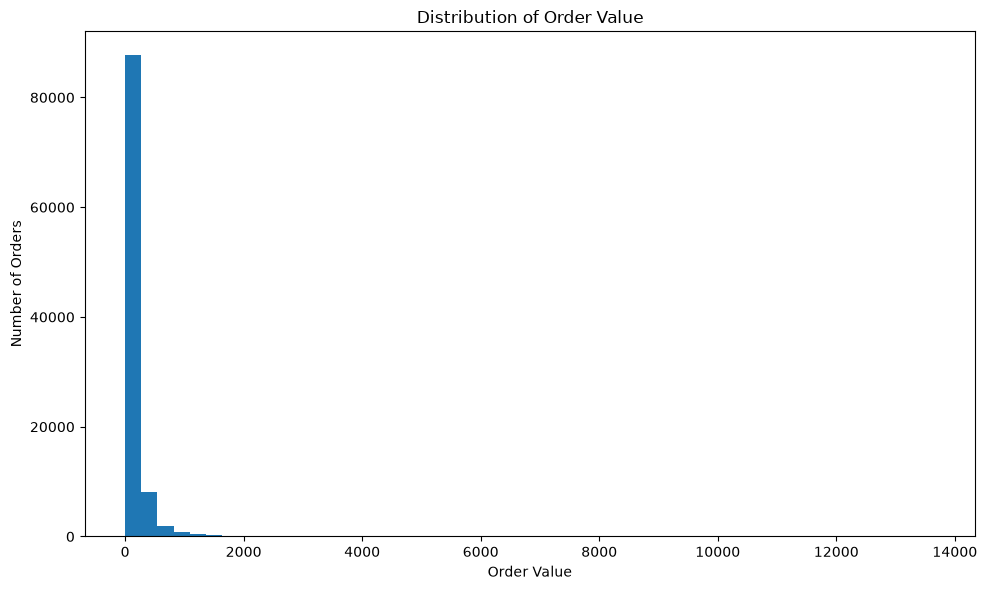

In [41]:
plt.figure(figsize=(10, 6))

plt.hist(
    order_df["total_order_value"].dropna(),
    bins=50
)

plt.title("Distribution of Order Value")
plt.xlabel("Order Value")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

In [42]:
order_status = (
    order_df["order_status"]
    .value_counts()
)

order_status

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [43]:
order_status_percentage = (
    order_df["order_status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

order_status_percentage

order_status
delivered      97.02
shipped         1.11
canceled        0.63
unavailable     0.61
invoiced        0.32
processing      0.30
created         0.01
approved        0.00
Name: proportion, dtype: float64

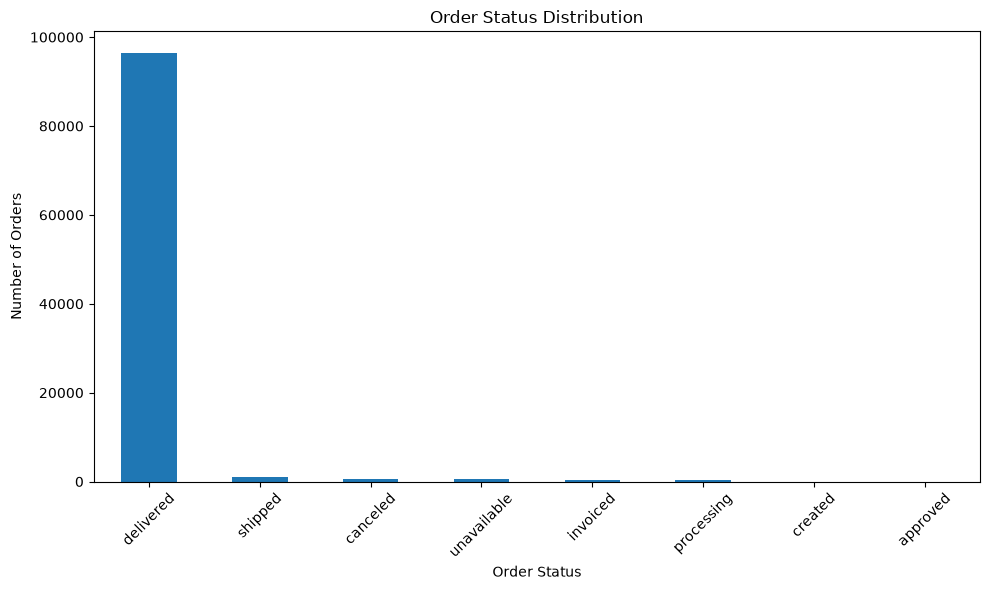

In [44]:
plt.figure(figsize=(10, 6))

order_status.plot(kind="bar")

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [45]:
revenue_by_status = (
    order_df
    .groupby("order_status")["total_order_value"]
    .sum()
    .sort_values(ascending=False)
)

revenue_by_status

order_status
delivered      15419773.75
shipped          177129.34
canceled         105885.72
processing        69394.11
invoiced          68988.75
unavailable        2140.49
approved            241.08
created               0.00
Name: total_order_value, dtype: float64

In [46]:
top_orders = (
    order_df[
        [
            "order_id",
            "customer_id",
            "total_order_value",
            "order_status"
        ]
    ]
    .sort_values(
        "total_order_value",
        ascending=False
    )
    .head(10)
)

top_orders

,order_id,customer_id,total_order_value,order_status
1471,03caa2c082116e1d31e67e9ae3700499,1617b1357756262bfa56ab541c47bc16,13664.08,delivered
44830,736e1922ae60d0d6a89247b851902527,ec5b2ba62e574342386871631fafd3fc,7274.88,delivered
3156,0812eb902a67711a1cb742b3cdaa65ae,c6e2731c5b391845f6800c97401a43a9,6929.31,delivered
99072,fefacc66af859508bf1a7934eab1e97f,f48d464a0baaea338cb25f816991ab1f,6922.21,delivered
95187,f5136e38d1a14a4dbd87dff67da82701,3fd6777bbce08a352fddd04e4a7cc8f6,6726.66,delivered
17255,2cc9089445046817a7539d90805e6e5a,05455dfa7cd02f13d132aa7a6a9729c6,6081.54,delivered
65576,a96610ab360d42a2e5335a3998b4718a,df55c14d1476a9a3467f131269c2477f,4950.34,delivered
70098,b4c4b76c642808cbe472a32b86cddc95,e0a2412720e9ea4f26c1ac985f6a7358,4809.44,canceled
9941,199af31afc78c699f0dbf71fb178d4d4,24bbf5fd2f2e1b359ee7de94defc4a15,4764.34,delivered
54793,8dbc85d1447242f3b127dda390d56e19,3d979689f636322c62418b6346b1c6d2,4681.78,delivered


In [47]:
category_df.head()

,product_category_name,order_count,item_count,category_revenue,avg_item_value
0,agro_industria_e_comercio,182,212,78374.07,369.689009
1,alimentos,450,510,36664.44,71.891059
2,alimentos_bebidas,227,278,19687.47,70.818237
3,artes,202,209,28247.81,135.156986
4,artes_e_artesanato,23,24,2184.14,91.005833


In [48]:
category_df.describe().T

,count,mean,std,min,25%,50%,75%,max
order_count,74.0,1344.189189,2236.901175,2.000000,76.000000,246.00000,1406.500000,9.417000e+03
item_count,74.0,1522.297297,2564.979835,2.000000,77.750000,279.50000,1669.000000,1.111500e+04
category_revenue,74.0,214102.070811,346076.608132,324.510000,9430.392500,53122.98500,209529.300000,1.441248e+06
avg_item_value,74.0,167.892142,150.480283,39.019333,98.920997,134.77647,176.257039,1.146795e+03


In [49]:
top_categories = (
    category_df
    .sort_values(
        "category_revenue",
        ascending=False
    )
    .head(10)
)

top_categories[
    [
        "product_category_name",
        "category_revenue",
        "order_count",
        "item_count",
        "avg_item_value"
    ]
]

,product_category_name,category_revenue,order_count,item_count,avg_item_value
11,beleza_saude,1441248.07,8836,9670,149.043234
66,relogios_presentes,1305541.61,5624,5991,217.917144
13,cama_mesa_banho,1241681.72,9417,11115,111.712256
32,esporte_lazer,1156656.48,7720,8641,133.856785
44,informatica_acessorios,1059272.40,6689,7827,135.335684
54,moveis_decoracao,902511.79,6449,8334,108.292751
73,utilidades_domesticas,778397.77,5884,6964,111.774522
26,cool_stuff,719329.95,3632,3796,189.496826
8,automotivo,685384.32,3897,4235,161.838092
40,ferramentas_jardim,584219.21,3518,4347,134.395954


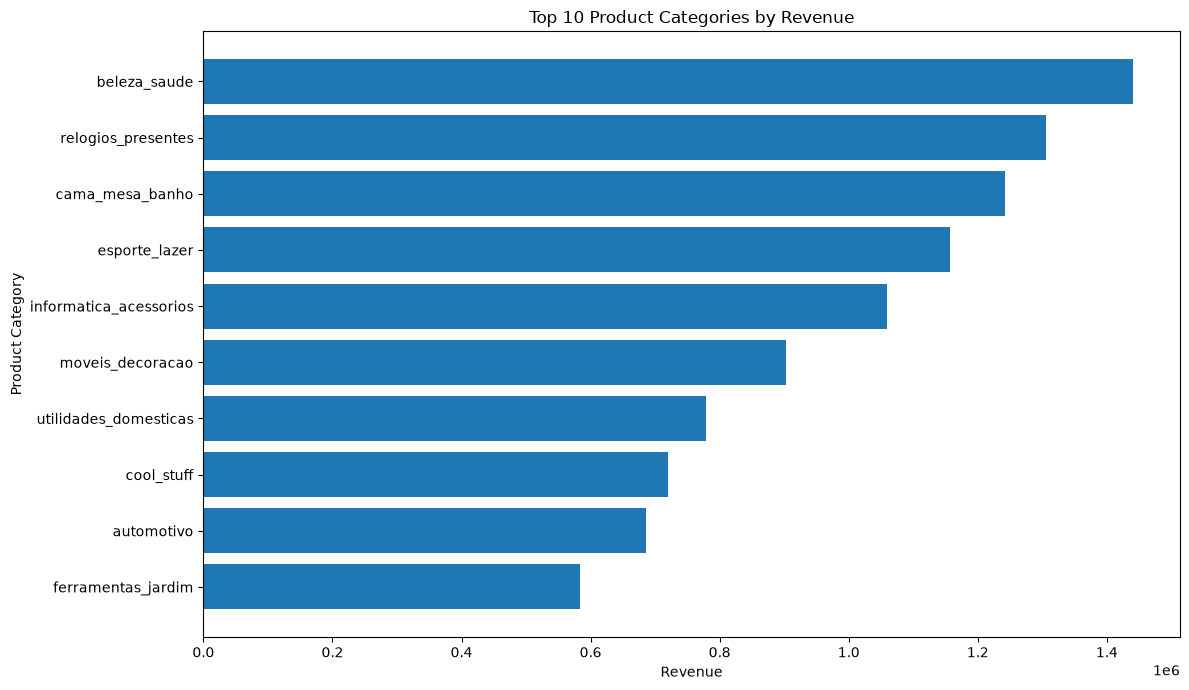

In [50]:
plot_data = (
    top_categories
    .sort_values("category_revenue")
)

plt.figure(figsize=(12, 7))

plt.barh(
    plot_data["product_category_name"],
    plot_data["category_revenue"]
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

In [51]:
top_categories_orders = (
    category_df
    .sort_values(
        "order_count",
        ascending=False
    )
    .head(10)
)

top_categories_orders[
    [
        "product_category_name",
        "order_count",
        "category_revenue"
    ]
]

,product_category_name,order_count,category_revenue
13,cama_mesa_banho,9417,1241681.72
11,beleza_saude,8836,1441248.07
32,esporte_lazer,7720,1156656.48
44,informatica_acessorios,6689,1059272.40
54,moveis_decoracao,6449,902511.79
73,utilidades_domesticas,5884,778397.77
66,relogios_presentes,5624,1305541.61
70,telefonia,4199,394883.32
8,automotivo,3897,685384.32
12,brinquedos,3886,561372.55


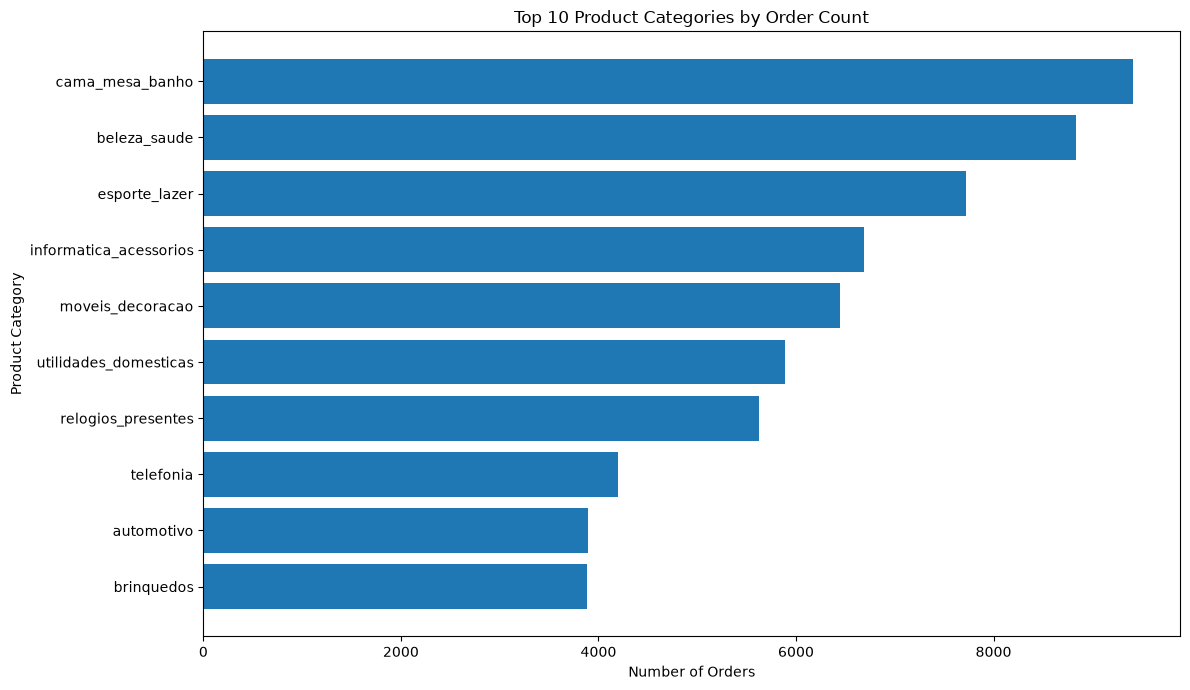

In [52]:
plot_data = (
    top_categories_orders
    .sort_values("order_count")
)

plt.figure(figsize=(12, 7))

plt.barh(
    plot_data["product_category_name"],
    plot_data["order_count"]
)

plt.title("Top 10 Product Categories by Order Count")
plt.xlabel("Number of Orders")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

In [53]:
highest_value_categories = (
    category_df
    .sort_values(
        "avg_item_value",
        ascending=False
    )
    .head(10)
)

highest_value_categories[
    [
        "product_category_name",
        "avg_item_value",
        "category_revenue",
        "order_count"
    ]
]

,product_category_name,avg_item_value,category_revenue,order_count
61,pcs,1146.795222,232799.43,181
64,portateis_casa_forno_e_cafe,660.441711,50193.57,75
29,eletrodomesticos_2,520.663529,123917.92,234
0,agro_industria_e_comercio,369.689009,78374.07,182
45,instrumentos_musicais,309.025544,210137.37,628
31,eletroportateis,304.372356,206668.83,630
65,portateis_cozinha_e_preparadores_de_alimentos,285.219333,4278.29,14
71,telefonia_fixa,243.260644,64220.81,217
25,construcao_ferramentas_seguranca,229.193918,44463.62,167
56,moveis_quarto,226.247798,24661.01,95


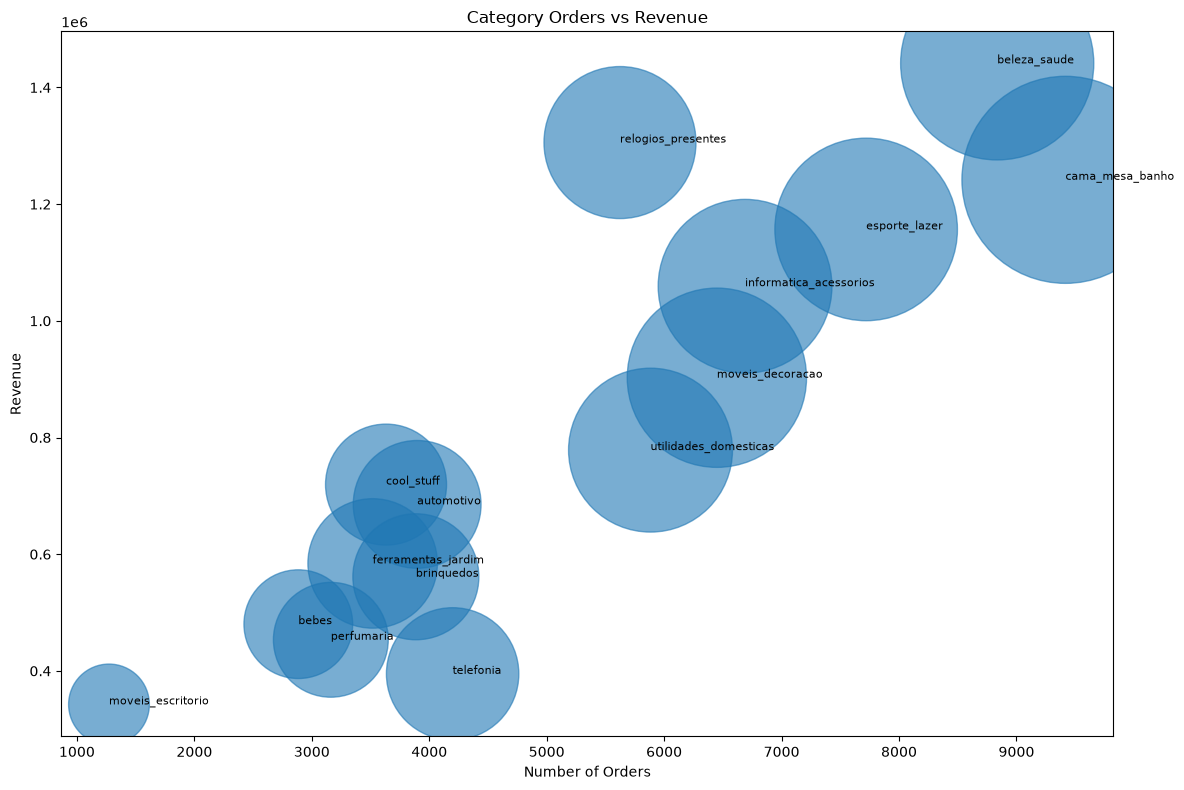

In [54]:
top_15 = (
    category_df
    .sort_values(
        "category_revenue",
        ascending=False
    )
    .head(15)
)

plt.figure(figsize=(12, 8))

plt.scatter(
    top_15["order_count"],
    top_15["category_revenue"],
    s=top_15["item_count"] * 2,
    alpha=0.6
)

for _, row in top_15.iterrows():
    plt.annotate(
        row["product_category_name"],
        (
            row["order_count"],
            row["category_revenue"]
        ),
        fontsize=8
    )

plt.title("Category Orders vs Revenue")
plt.xlabel("Number of Orders")
plt.ylabel("Revenue")

plt.tight_layout()
plt.show()

In [55]:
customer_df.head()


,customer_id,customer_order_count,customer_total_spending,average_order_value,repeat_customer
0,00012a2ce6f8dcda20d059ce98491703,1,114.74,114.74,0
1,000161a058600d5901f007fab4c27140,1,67.41,67.41,0
2,0001fd6190edaaf884bcaf3d49edf079,1,195.42,195.42,0
3,0002414f95344307404f0ace7a26f1d5,1,179.35,179.35,0
4,000379cdec625522490c315e70c7a9fb,1,107.01,107.01,0


In [56]:
customer_df.describe().T

,count,mean,std,min,25%,50%,75%,max
customer_order_count,99441.0,1.000000,0.000000,1.0,1.00,1.00,1.0,1.00
customer_total_spending,99441.0,159.326166,220.058804,0.0,61.05,104.56,176.0,13664.08
average_order_value,99441.0,159.326166,220.058804,0.0,61.05,104.56,176.0,13664.08
repeat_customer,99441.0,0.000000,0.000000,0.0,0.00,0.00,0.0,0.00


In [57]:
total_customers = customer_df["customer_id"].nunique()

print(f"Total Customers: {total_customers:,}")

Total Customers: 99,441


In [58]:
customer_order_distribution = (
    customer_df["customer_order_count"]
    .value_counts()
    .sort_index()
)

customer_order_distribution.head(20)

customer_order_count
1    99441
Name: count, dtype: int64

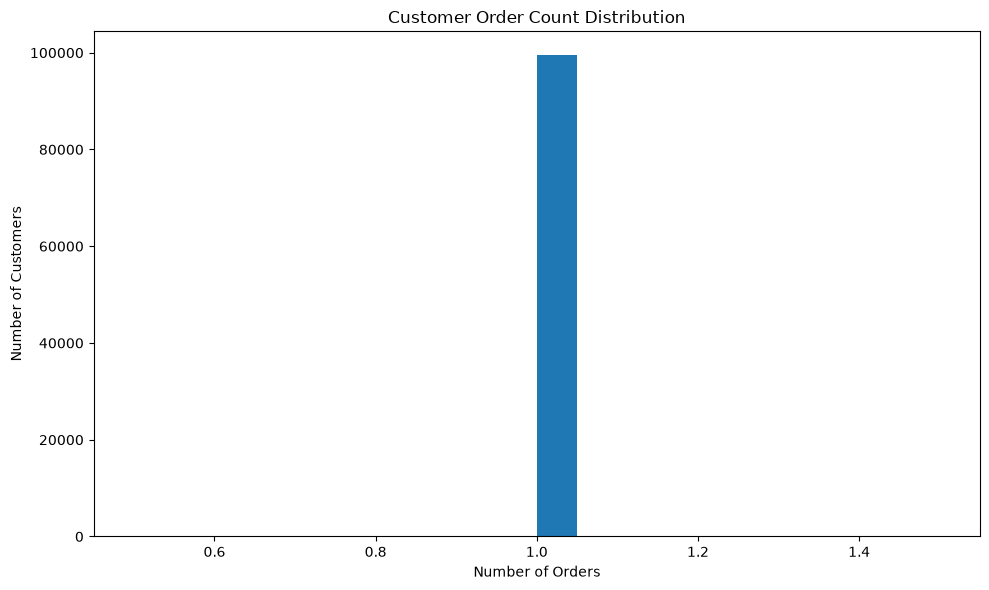

In [59]:
plt.figure(figsize=(10, 6))

plt.hist(
    customer_df["customer_order_count"],
    bins=20
)

plt.title("Customer Order Count Distribution")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [60]:
repeat_customer_count = (
    customer_df["repeat_customer"]
    .value_counts()
    .sort_index()
)

repeat_customer_count

repeat_customer
0    99441
Name: count, dtype: int64

In [61]:
repeat_customer_percentage = (
    customer_df["repeat_customer"].mean() * 100
)

print(
    f"Repeat Customer Percentage: "
    f"{repeat_customer_percentage:.2f}%"
)

Repeat Customer Percentage: 0.00%


In [62]:
customer_type = pd.Series({
    "New Customer": (
        customer_df["repeat_customer"] == 0
    ).sum(),

    "Repeat Customer": (
        customer_df["repeat_customer"] == 1
    ).sum()
})

customer_type

New Customer       99441
Repeat Customer        0
dtype: int64

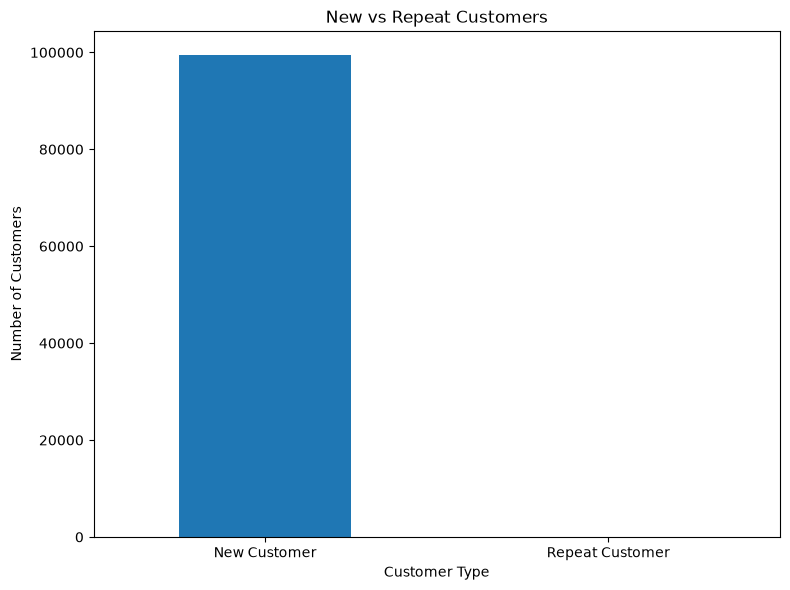

In [63]:
plt.figure(figsize=(8, 6))

customer_type.plot(kind="bar")

plt.title("New vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [65]:
top_customers = (
    customer_df
    .sort_values(
        "customer_total_spending",
        ascending=False
    )
    .head(10)
)

top_customers[
    [
        "customer_id",
        "customer_order_count",
        "customer_total_spending",
        "average_order_value",
        "repeat_customer"
    ]
]

,customer_id,customer_order_count,customer_total_spending,average_order_value,repeat_customer
8546,1617b1357756262bfa56ab541c47bc16,1,13664.08,13664.08,0
91985,ec5b2ba62e574342386871631fafd3fc,1,7274.88,7274.88,0
77522,c6e2731c5b391845f6800c97401a43a9,1,6929.31,6929.31,0
95124,f48d464a0baaea338cb25f816991ab1f,1,6922.21,6922.21,0
24771,3fd6777bbce08a352fddd04e4a7cc8f6,1,6726.66,6726.66,0
2065,05455dfa7cd02f13d132aa7a6a9729c6,1,6081.54,6081.54,0
86908,df55c14d1476a9a3467f131269c2477f,1,4950.34,4950.34,0
87397,e0a2412720e9ea4f26c1ac985f6a7358,1,4809.44,4809.44,0
14282,24bbf5fd2f2e1b359ee7de94defc4a15,1,4764.34,4764.34,0
23932,3d979689f636322c62418b6346b1c6d2,1,4681.78,4681.78,0


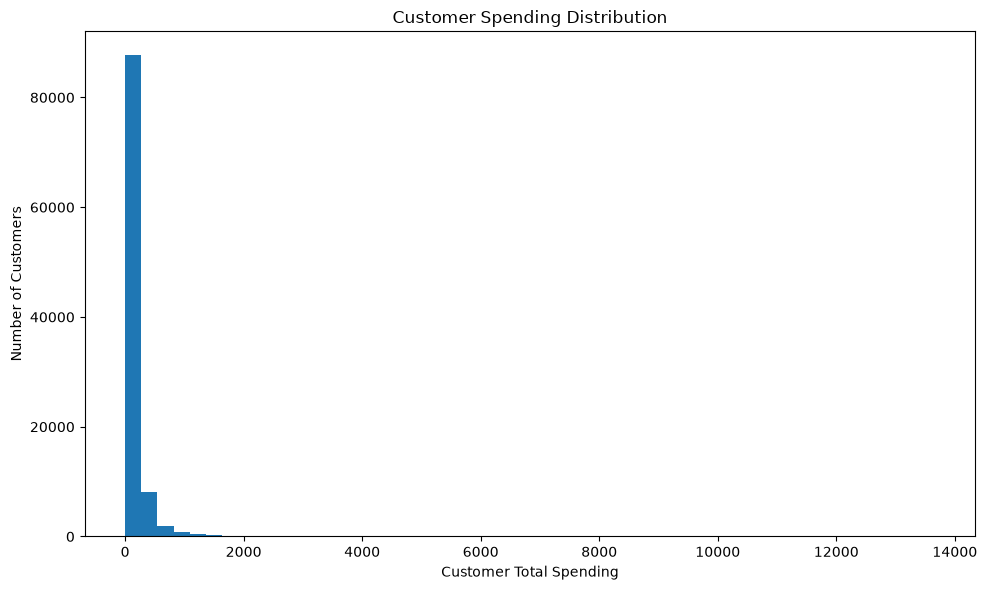

In [66]:
plt.figure(figsize=(10, 6))

plt.hist(
    customer_df["customer_total_spending"].dropna(),
    bins=50
)

plt.title("Customer Spending Distribution")
plt.xlabel("Customer Total Spending")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [67]:
repeat_spending = (
    customer_df
    .groupby("repeat_customer")
    ["customer_total_spending"]
    .mean()
)

repeat_spending

repeat_customer
0    159.326166
Name: customer_total_spending, dtype: float64

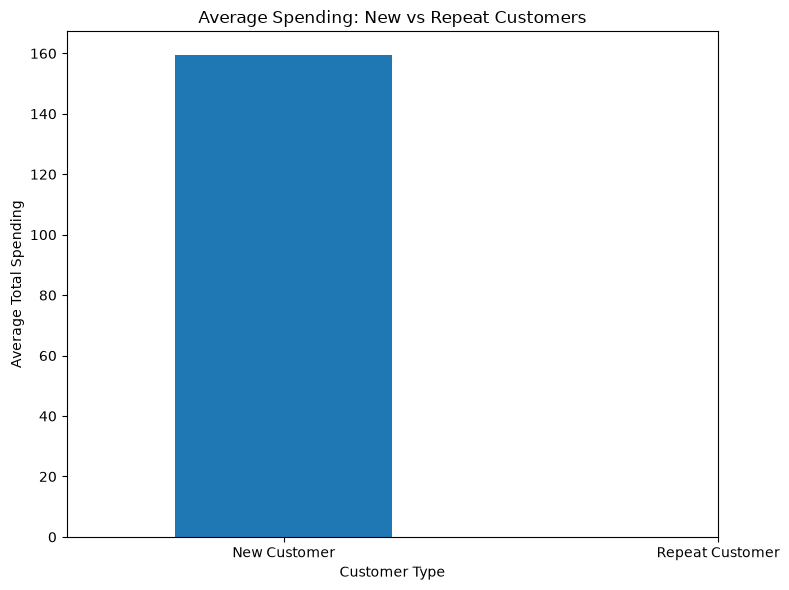

In [68]:
plt.figure(figsize=(8, 6))

repeat_spending.plot(kind="bar")

plt.title("Average Spending: New vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Average Total Spending")
plt.xticks(
    [0, 1],
    ["New Customer", "Repeat Customer"],
    rotation=0
)

plt.tight_layout()
plt.show()

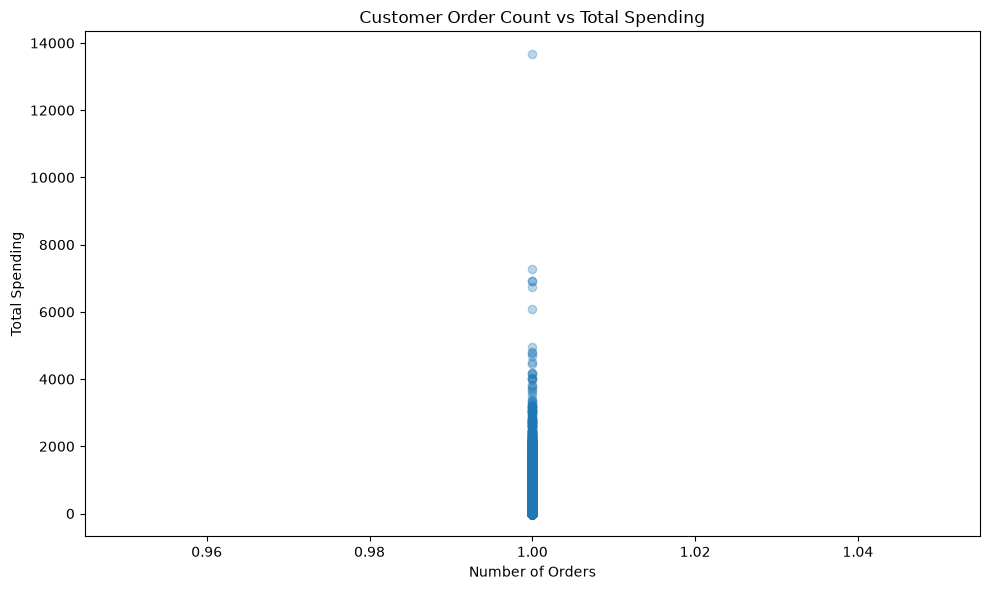

In [69]:
plt.figure(figsize=(10, 6))

plt.scatter(
    customer_df["customer_order_count"],
    customer_df["customer_total_spending"],
    alpha=0.3
)

plt.title("Customer Order Count vs Total Spending")
plt.xlabel("Number of Orders")
plt.ylabel("Total Spending")

plt.tight_layout()
plt.show()

In [70]:
order_status = order_df["order_status"].value_counts()

print(order_status)

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


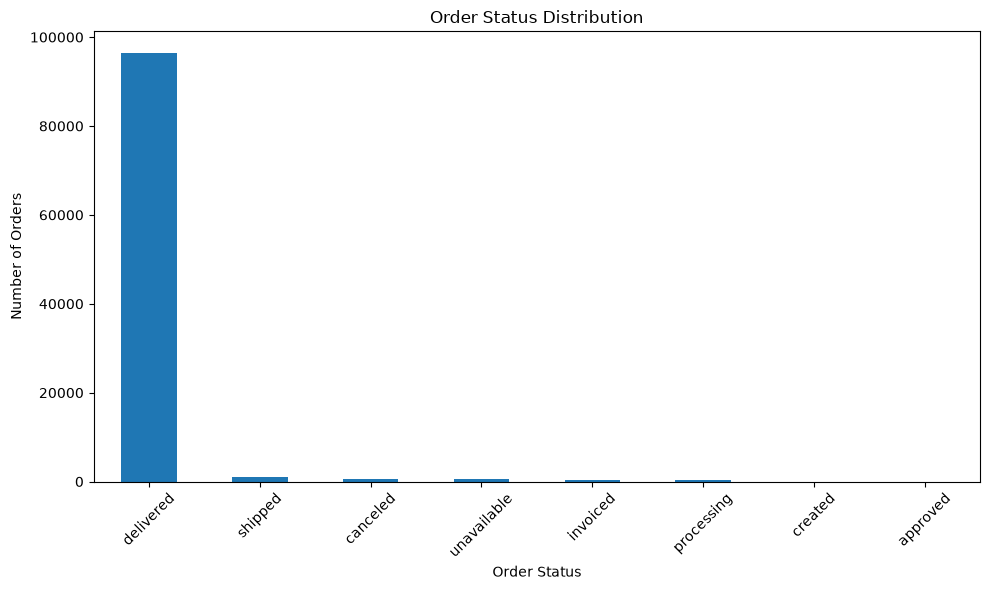

In [71]:
plt.figure(figsize=(10, 6))

order_status.plot(kind="bar")

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [72]:
payment_type = order_df["payment_type"].value_counts()

print(payment_type)

payment_type
credit_card    76504
boleto         19784
voucher         1621
debit_card      1528
not_defined        3
Name: count, dtype: int64


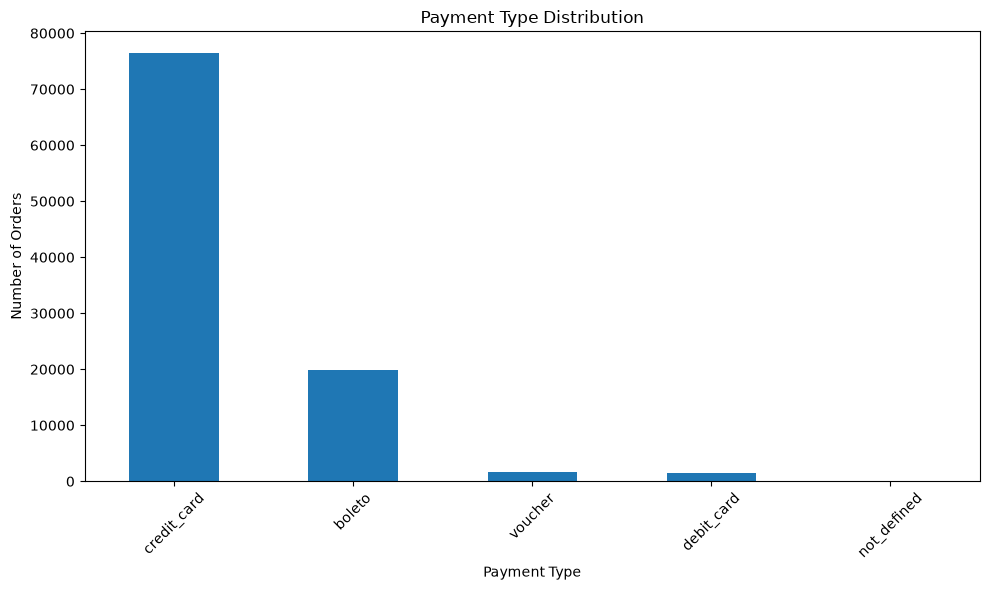

In [73]:
plt.figure(figsize=(10, 6))

payment_type.plot(kind="bar")

plt.title("Payment Type Distribution")
plt.xlabel("Payment Type")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [74]:
delivery_status = order_df["delivery_status"].value_counts()

print(delivery_status)

delivery_status
On Time          88649
Delayed           7827
Not Delivered     2965
Name: count, dtype: int64


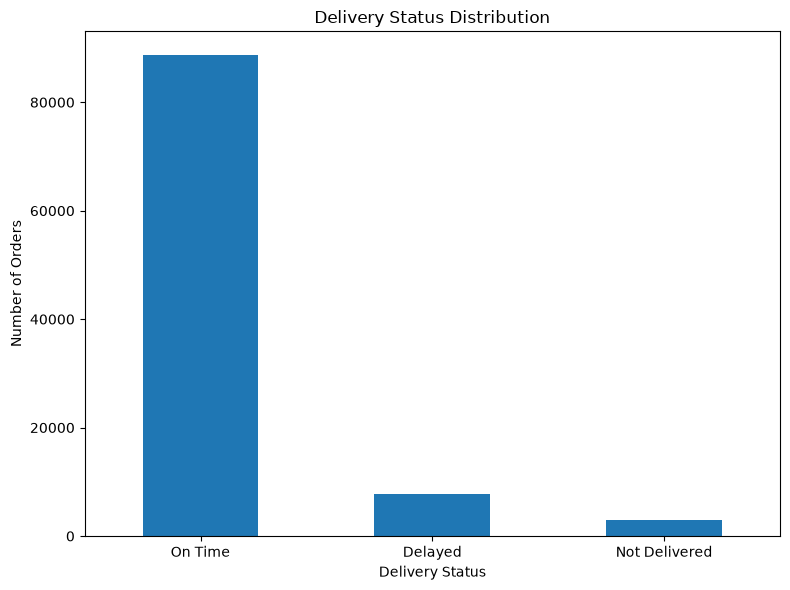

In [75]:
plt.figure(figsize=(8, 6))

delivery_status.plot(kind="bar")

plt.title("Delivery Status Distribution")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [76]:
review_score = (
    order_df["avg_review_score"]
    .round()
    .value_counts()
    .sort_index()
)

print(review_score)

avg_review_score
1.0    11316
2.0     3167
3.0     8137
4.0    19098
5.0    56955
Name: count, dtype: int64


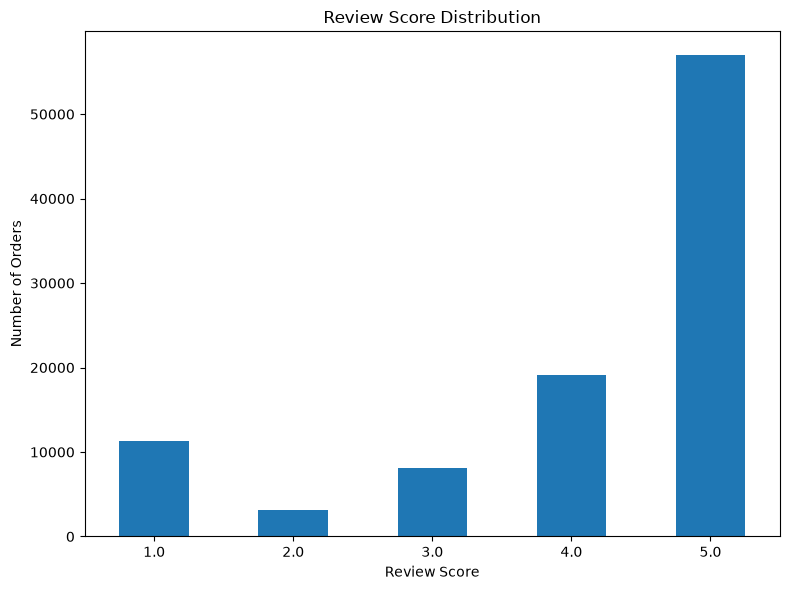

In [77]:
plt.figure(figsize=(8, 6))

review_score.plot(kind="bar")

plt.title("Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

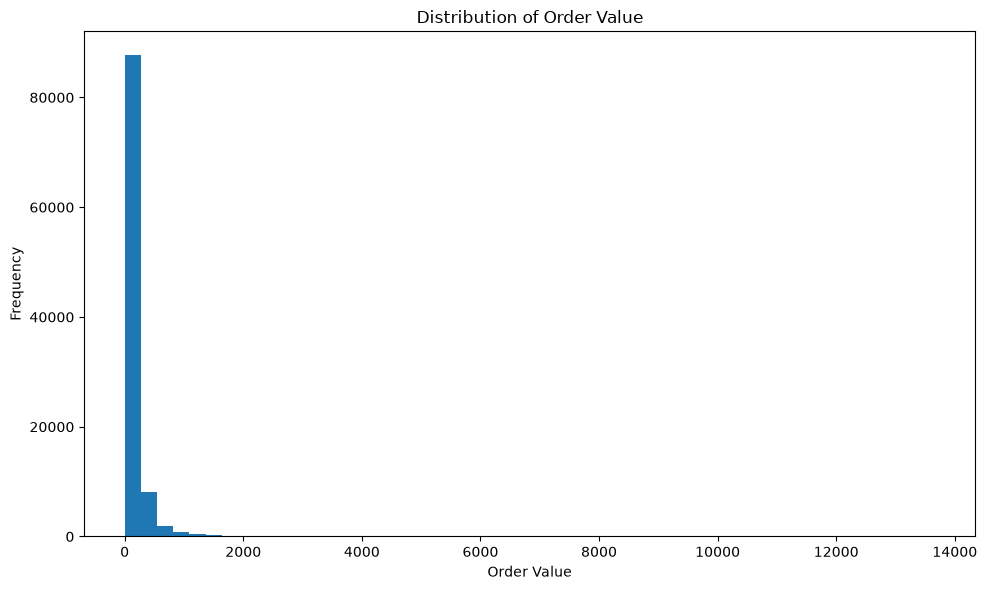

In [78]:
plt.figure(figsize=(10, 6))

plt.hist(
    order_df["total_order_value"].dropna(),
    bins=50
)

plt.title("Distribution of Order Value")
plt.xlabel("Order Value")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

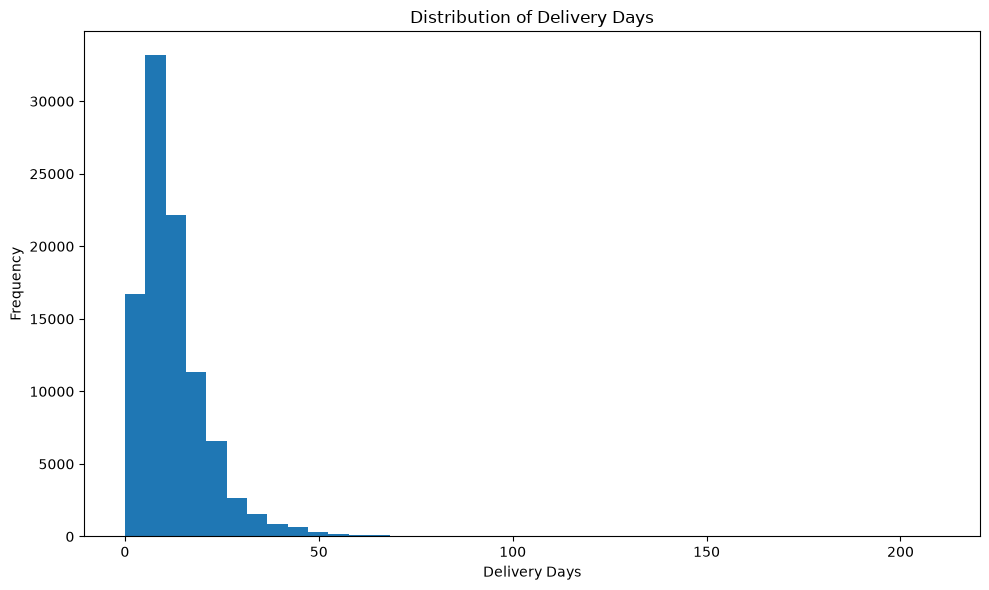

In [79]:
plt.figure(figsize=(10, 6))

plt.hist(
    order_df["delivery_days"].dropna(),
    bins=40
)

plt.title("Distribution of Delivery Days")
plt.xlabel("Delivery Days")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

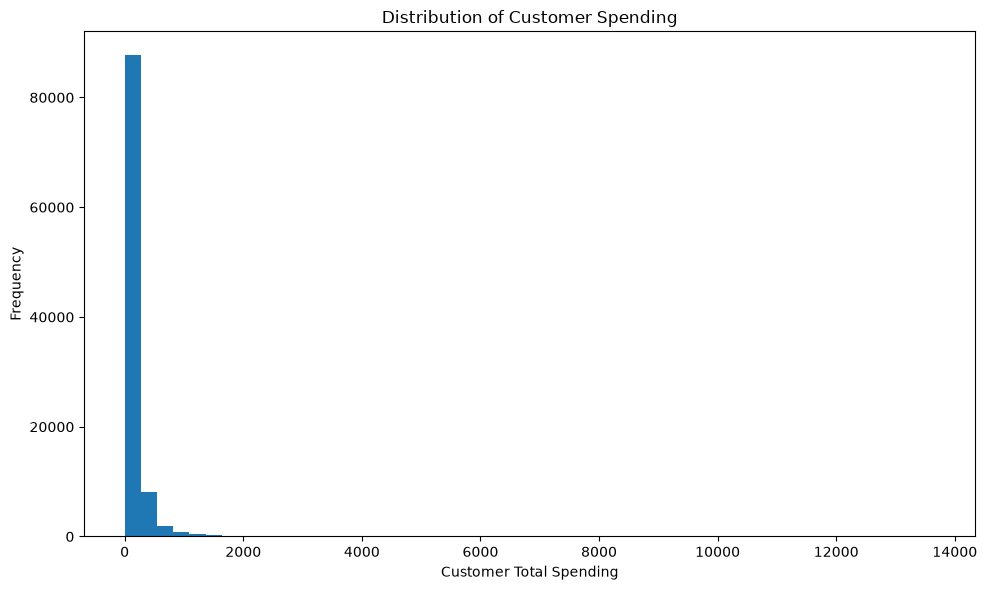

In [80]:
plt.figure(figsize=(10, 6))

plt.hist(
    customer_df["customer_total_spending"].dropna(),
    bins=50
)

plt.title("Distribution of Customer Spending")
plt.xlabel("Customer Total Spending")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

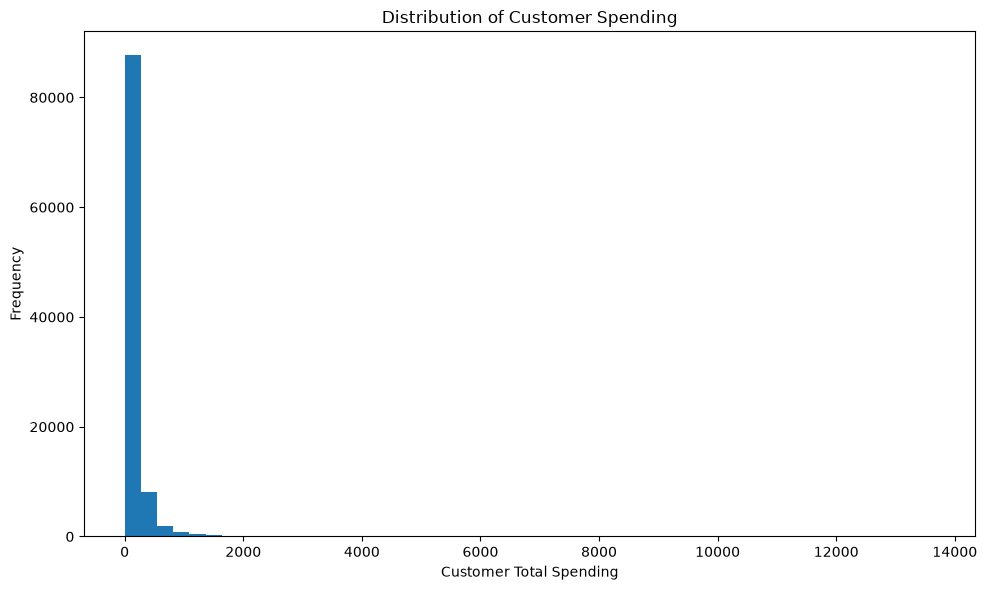

In [81]:
plt.figure(figsize=(10, 6))

plt.hist(
    customer_df["customer_total_spending"].dropna(),
    bins=50
)

plt.title("Distribution of Customer Spending")
plt.xlabel("Customer Total Spending")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [82]:
order_df[
    [
        "total_order_value",
        "delivery_days",
        "delivery_delay_days",
        "avg_review_score"
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
total_order_value,99441.0,159.326166,220.058804,0.0,61.05,104.56,176.0,13664.08
delivery_days,96476.0,12.497336,9.555460,0.0,7.00,10.00,16.0,210.00
delivery_delay_days,96476.0,0.719391,4.652564,0.0,0.00,0.00,0.0,188.00
avg_review_score,98673.0,4.086793,1.346274,1.0,4.00,5.00,5.0,5.00


In [83]:
delivery_review = (
    order_df
    .groupby("delivery_status")["avg_review_score"]
    .mean()
)

delivery_review

delivery_status
Delayed          2.566562
Not Delivered    1.753254
On Time          4.294151
Name: avg_review_score, dtype: float64

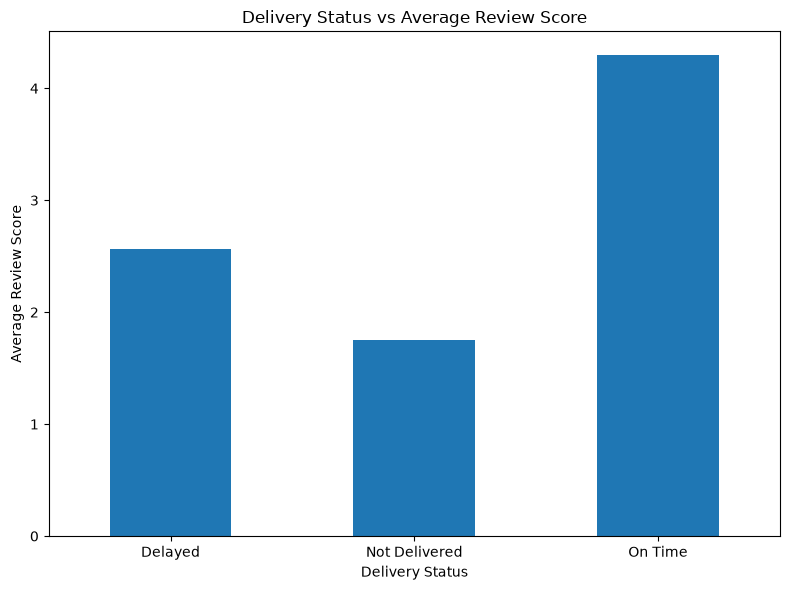

In [84]:
plt.figure(figsize=(8, 6))

delivery_review.plot(kind="bar")

plt.title("Delivery Status vs Average Review Score")
plt.xlabel("Delivery Status")
plt.ylabel("Average Review Score")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

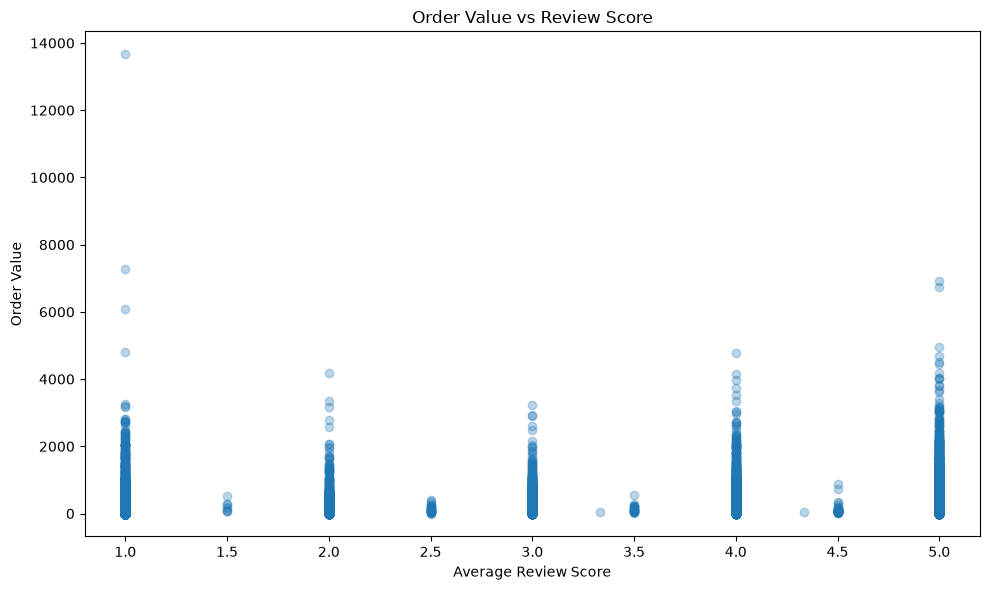

In [85]:
plt.figure(figsize=(10, 6))

plt.scatter(
    order_df["avg_review_score"],
    order_df["total_order_value"],
    alpha=0.3
)

plt.title("Order Value vs Review Score")
plt.xlabel("Average Review Score")
plt.ylabel("Order Value")

plt.tight_layout()
plt.show()

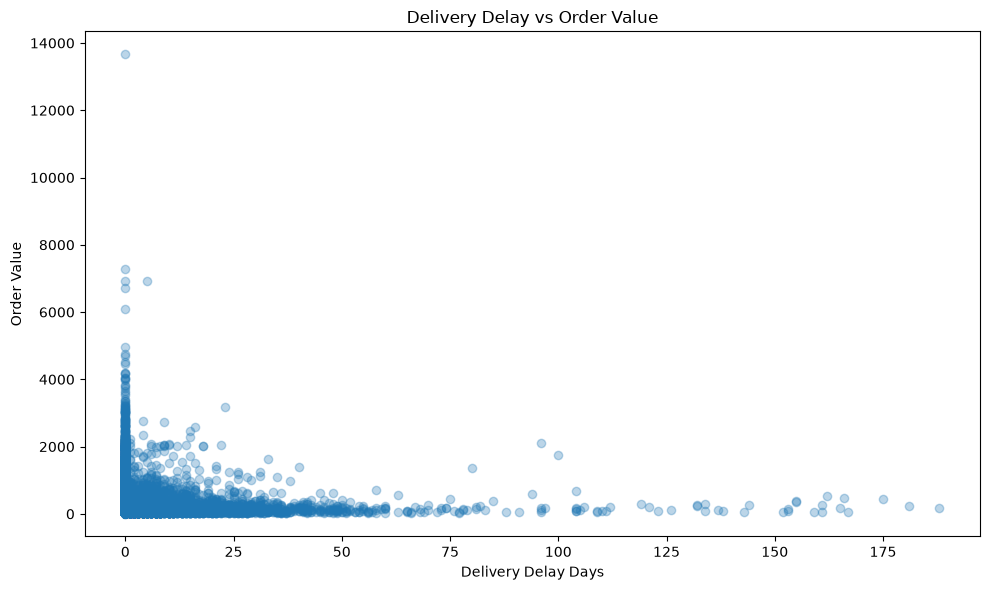

In [86]:
plt.figure(figsize=(10, 6))

plt.scatter(
    order_df["delivery_delay_days"],
    order_df["total_order_value"],
    alpha=0.3
)

plt.title("Delivery Delay vs Order Value")
plt.xlabel("Delivery Delay Days")
plt.ylabel("Order Value")

plt.tight_layout()
plt.show()

In [87]:
category_analysis = (
    category_df[
        [
            "product_category_name",
            "category_revenue",
            "order_count",
            "item_count",
            "avg_item_value"
        ]
    ]
    .sort_values(
        "category_revenue",
        ascending=False
    )
    .head(15)
)

category_analysis

,product_category_name,category_revenue,order_count,item_count,avg_item_value
11,beleza_saude,1441248.07,8836,9670,149.043234
66,relogios_presentes,1305541.61,5624,5991,217.917144
13,cama_mesa_banho,1241681.72,9417,11115,111.712256
32,esporte_lazer,1156656.48,7720,8641,133.856785
44,informatica_acessorios,1059272.40,6689,7827,135.335684
54,moveis_decoracao,902511.79,6449,8334,108.292751
73,utilidades_domesticas,778397.77,5884,6964,111.774522
26,cool_stuff,719329.95,3632,3796,189.496826
8,automotivo,685384.32,3897,4235,161.838092
40,ferramentas_jardim,584219.21,3518,4347,134.395954


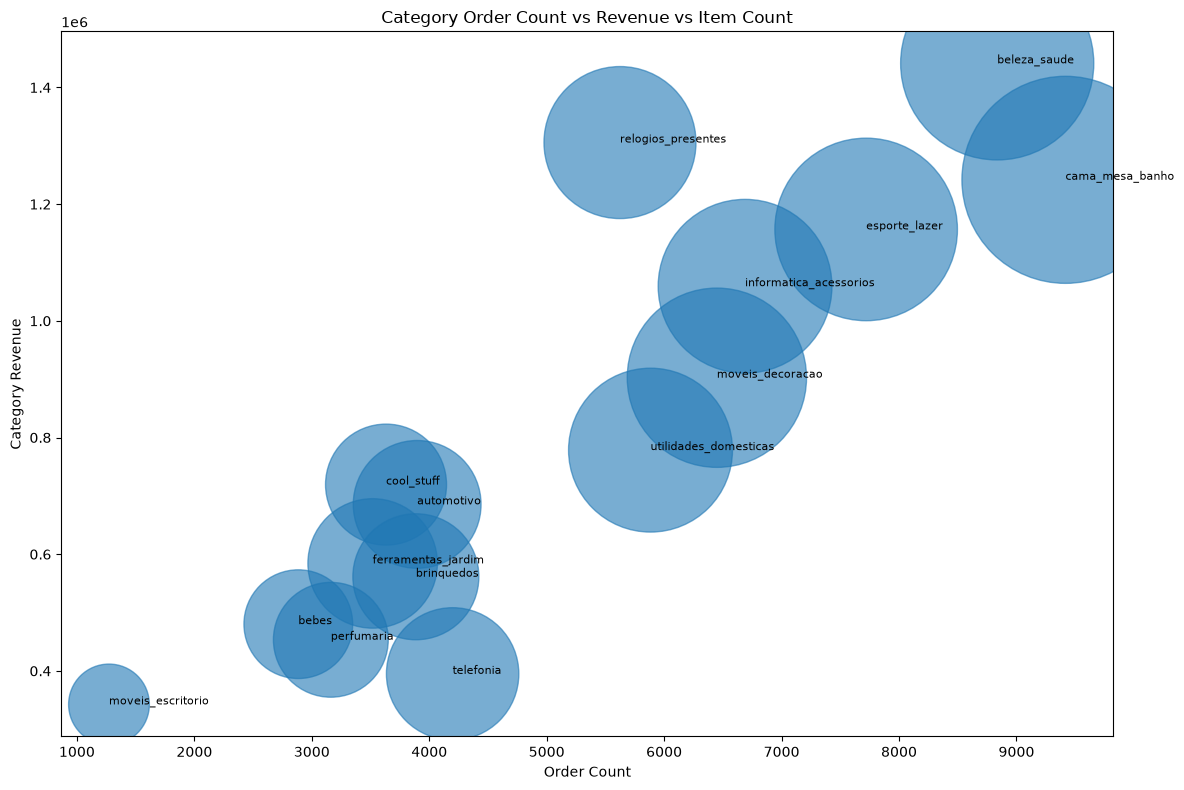

In [88]:
plt.figure(figsize=(12, 8))

plt.scatter(
    category_analysis["order_count"],
    category_analysis["category_revenue"],
    s=category_analysis["item_count"] * 2,
    alpha=0.6
)

for _, row in category_analysis.iterrows():

    plt.annotate(
        row["product_category_name"],
        (
            row["order_count"],
            row["category_revenue"]
        ),
        fontsize=8
    )

plt.title(
    "Category Order Count vs Revenue vs Item Count"
)

plt.xlabel("Order Count")
plt.ylabel("Category Revenue")

plt.tight_layout()
plt.show()

In [89]:
order_df["order_purchase_timestamp"] = pd.to_datetime(
    order_df["order_purchase_timestamp"],
    errors="coerce"
)

order_df["purchase_month"] = (
    order_df["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

order_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,total_order_value,delivery_days,delivery_delay_days,delivery_status,customer_order_count,customer_total_spending,average_order_value,repeat_customer,avg_review_score,payment_type,purchase_month
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29,72.19,7.0,0.0,On Time,1,72.19,72.19,0,5.0,credit_card,2017-09
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15,259.83,16.0,0.0,On Time,1,259.83,259.83,0,4.0,credit_card,2017-04
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05,216.87,8.0,0.0,On Time,1,216.87,216.87,0,5.0,credit_card,2018-01
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-14 13:32:39,2018-08-20,25.78,6.0,0.0,On Time,1,25.78,25.78,0,4.0,credit_card,2018-08
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-03-01 16:42:31,2017-03-17,218.04,25.0,0.0,On Time,1,218.04,218.04,0,5.0,credit_card,2017-02


In [90]:
monthly_revenue = (
    order_df
    .groupby("purchase_month")["total_order_value"]
    .sum()
    .reset_index()
)

monthly_revenue.head()

,purchase_month,total_order_value
0,2016-09,354.75
1,2016-10,56808.84
2,2016-12,19.62
3,2017-01,137188.49
4,2017-02,286280.62


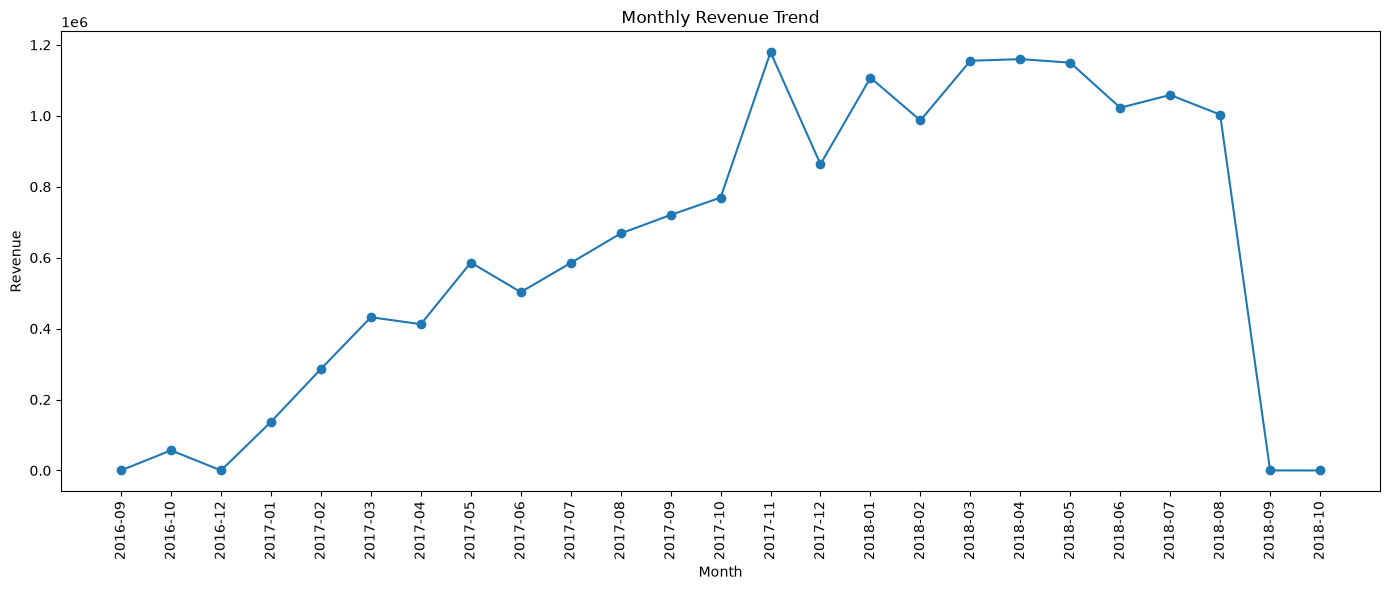

In [91]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_revenue["purchase_month"],
    monthly_revenue["total_order_value"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [92]:
monthly_orders = (
    order_df
    .groupby("purchase_month")["order_id"]
    .nunique()
    .reset_index(name="order_count")
)

monthly_orders.head()

,purchase_month,order_count
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780


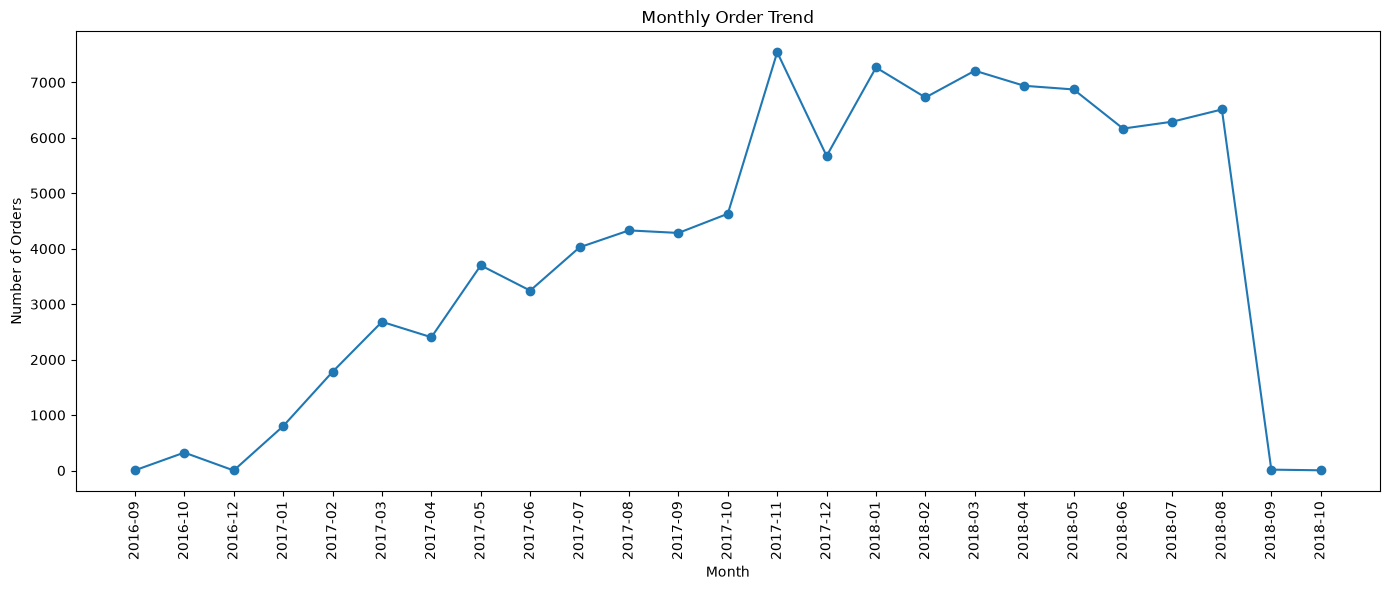

In [93]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_orders["purchase_month"],
    monthly_orders["order_count"],
    marker="o"
)

plt.title("Monthly Order Trend")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [94]:
monthly_aov = (
    order_df
    .groupby("purchase_month")["total_order_value"]
    .mean()
    .reset_index(name="average_order_value")
)

monthly_aov.head()

,purchase_month,average_order_value
0,2016-09,88.687500
1,2016-10,175.335926
2,2016-12,19.620000
3,2017-01,171.485613
4,2017-02,160.831809


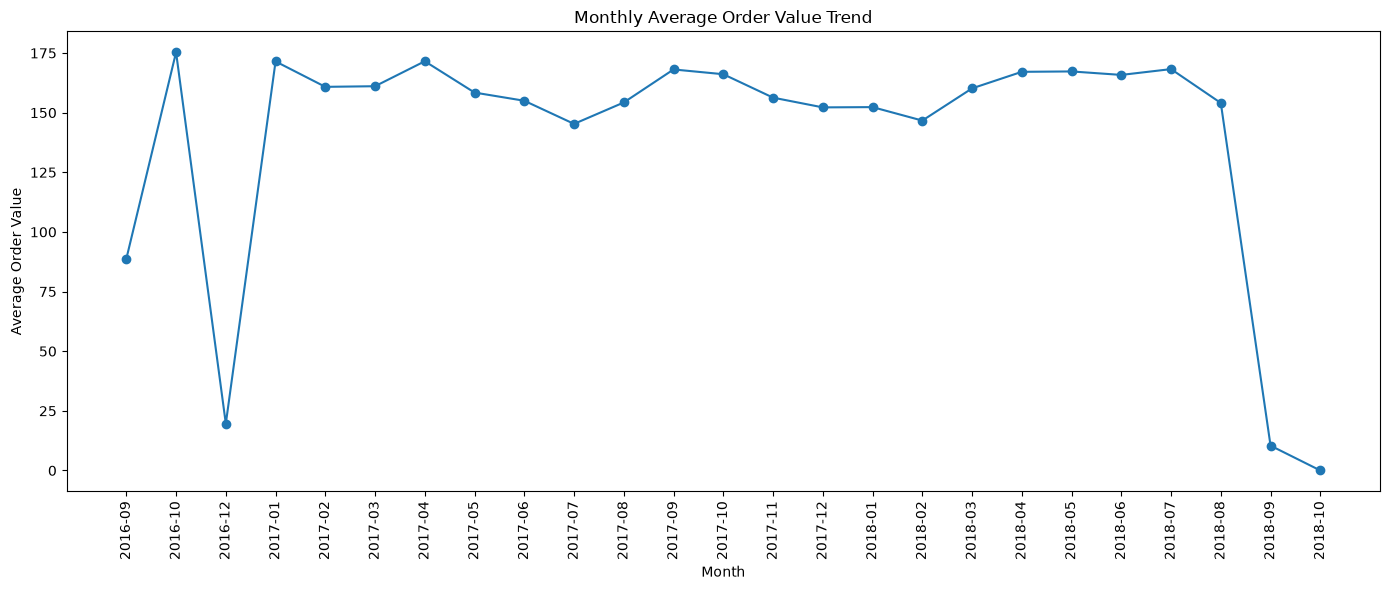

In [95]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_aov["purchase_month"],
    monthly_aov["average_order_value"],
    marker="o"
)

plt.title("Monthly Average Order Value Trend")
plt.xlabel("Month")
plt.ylabel("Average Order Value")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [96]:
numeric_df = order_df[
    [
        "total_order_value",
        "delivery_days",
        "delivery_delay_days",
        "customer_order_count",
        "customer_total_spending",
        "average_order_value",
        "repeat_customer",
        "avg_review_score"
    ]
]

numeric_df.corr()

,total_order_value,delivery_days,delivery_delay_days,customer_order_count,customer_total_spending,average_order_value,repeat_customer,avg_review_score
total_order_value,1.000000,0.069854,0.018289,NaN,1.000000,1.000000,NaN,-0.036005
delivery_days,0.069854,1.000000,0.698737,NaN,0.069854,0.069854,NaN,-0.334179
delivery_delay_days,0.018289,0.698737,1.000000,NaN,0.018289,0.018289,NaN,-0.263289
customer_order_count,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_total_spending,1.000000,0.069854,0.018289,NaN,1.000000,1.000000,NaN,-0.036005
average_order_value,1.000000,0.069854,0.018289,NaN,1.000000,1.000000,NaN,-0.036005
repeat_customer,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
avg_review_score,-0.036005,-0.334179,-0.263289,NaN,-0.036005,-0.036005,NaN,1.000000


In [97]:
correlation_matrix = numeric_df.corr()

correlation_matrix

,total_order_value,delivery_days,delivery_delay_days,customer_order_count,customer_total_spending,average_order_value,repeat_customer,avg_review_score
total_order_value,1.000000,0.069854,0.018289,NaN,1.000000,1.000000,NaN,-0.036005
delivery_days,0.069854,1.000000,0.698737,NaN,0.069854,0.069854,NaN,-0.334179
delivery_delay_days,0.018289,0.698737,1.000000,NaN,0.018289,0.018289,NaN,-0.263289
customer_order_count,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_total_spending,1.000000,0.069854,0.018289,NaN,1.000000,1.000000,NaN,-0.036005
average_order_value,1.000000,0.069854,0.018289,NaN,1.000000,1.000000,NaN,-0.036005
repeat_customer,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
avg_review_score,-0.036005,-0.334179,-0.263289,NaN,-0.036005,-0.036005,NaN,1.000000


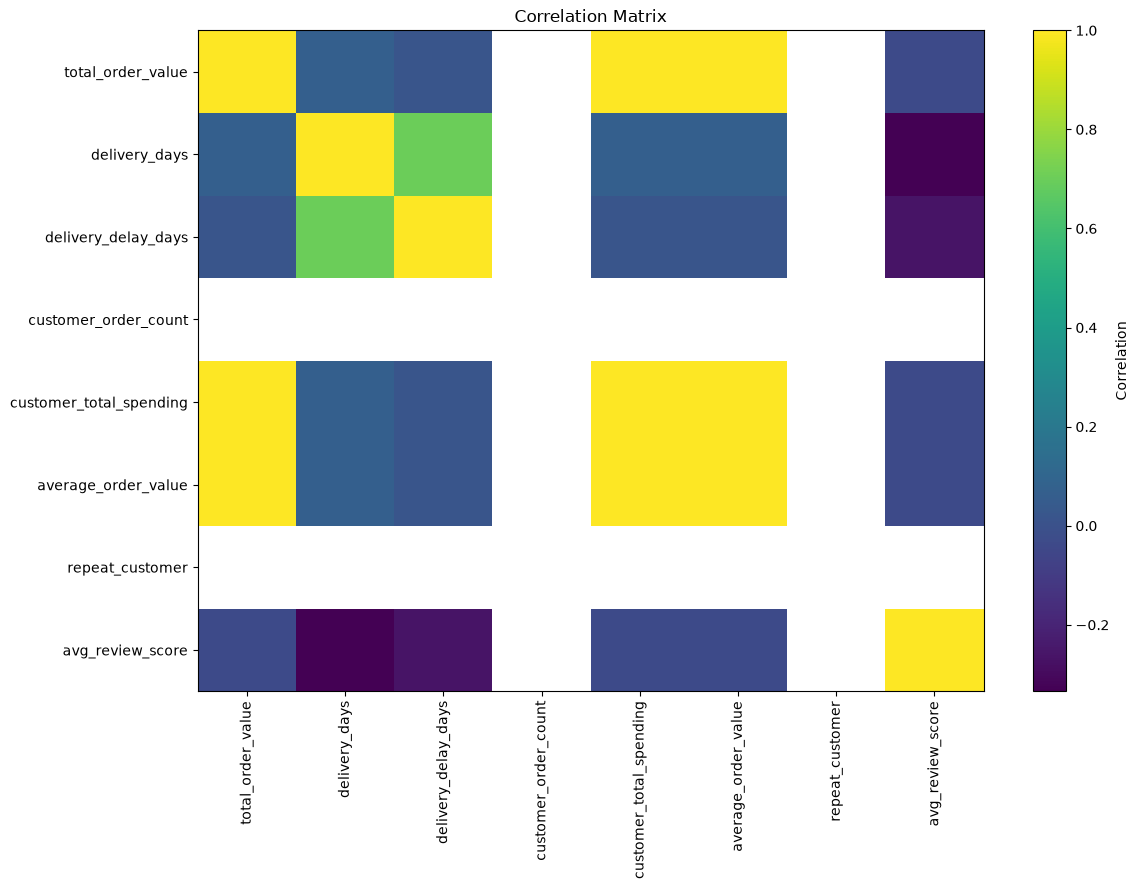

In [98]:
plt.figure(figsize=(12, 9))

plt.imshow(
    correlation_matrix,
    aspect="auto"
)

plt.colorbar(
    label="Correlation"
)

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.index)),
    correlation_matrix.index
)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()

In [99]:
total_orders = order_df["order_id"].nunique()

total_customers = customer_df["customer_id"].nunique()

total_sellers = seller_df["seller_id"].nunique()

total_revenue = order_df["total_order_value"].sum()

average_order_value = (
    order_df["total_order_value"].mean()
)

average_delivery_days = (
    order_df["delivery_days"].mean()
)

average_review_score = (
    order_df["avg_review_score"].mean()
)

repeat_customer_percentage = (
    customer_df["repeat_customer"].mean() * 100
)

print("========== EDA BUSINESS SUMMARY ==========")

print(f"Total Orders              : {total_orders:,}")
print(f"Total Customers           : {total_customers:,}")
print(f"Total Sellers             : {total_sellers:,}")
print(f"Total Revenue             : {total_revenue:,.2f}")
print(f"Average Order Value       : {average_order_value:,.2f}")
print(f"Average Delivery Days     : {average_delivery_days:.2f}")
print(f"Average Review Score      : {average_review_score:.2f}")
print(f"Repeat Customer Percentage: {repeat_customer_percentage:.2f}%")

========== EDA BUSINESS SUMMARY ==========
Total Orders              : 99,441
Total Customers           : 99,441
Total Sellers             : 3,095
Total Revenue             : 15,843,553.24
Average Order Value       : 159.33
Average Delivery Days     : 12.50
Average Review Score      : 4.09
Repeat Customer Percentage: 0.00%


Number of categories: 63
F-statistic: 175.56726052405648
P-value: 0.0

Decision: Reject H0
Conclusion: Average order value differs significantly across product categories.
